<a href="https://colab.research.google.com/github/chetankodigantiML/ECGR4105-F26/blob/main/HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [160]:
import torch
import matplotlib.pyplot as plt
from google.colab import drive
import numpy as np
import torch.optim as optim
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Problem 1

In [175]:
housing = pd.read_csv('/content/drive/My Drive/Fall26/ECGR4105/HW6/Housing.csv')

In [176]:
def binary_map(x):
  return x.map({'yes': 1, 'no': 0})

def furnish_map(x):
  return x.map({'furnished': 1, 'semi-furnished': 0.5, 'unfurnished': 0})

In [177]:
colms = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'price']
scaler = MinMaxScaler()
housing[colms] = scaler.fit_transform(housing[colms])

housing[['mainroad']] = housing[['mainroad']].apply(binary_map)
housing[['guestroom']] = housing[['guestroom']].apply(binary_map)
housing[['basement']] = housing[['basement']].apply(binary_map)
housing[['hotwaterheating']] = housing[['hotwaterheating']].apply(binary_map)
housing[['airconditioning']] = housing[['airconditioning']].apply(binary_map)
housing[['prefarea']] = housing[['prefarea']].apply(binary_map)
housing[['furnishingstatus']] = housing[['furnishingstatus']].apply(furnish_map)

housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,1.000000,0.396564,0.6,0.333333,0.666667,1,0,0,0,1,0.666667,1,1.0
1,0.909091,0.502405,0.6,1.000000,1.000000,1,0,0,0,1,1.000000,0,1.0
2,0.909091,0.571134,0.4,0.333333,0.333333,1,0,1,0,0,0.666667,1,0.5
3,0.906061,0.402062,0.6,0.333333,0.333333,1,0,1,0,1,1.000000,1,1.0
4,0.836364,0.396564,0.6,0.000000,0.333333,1,1,1,0,1,0.666667,0,1.0


In [290]:
h_tr, h_tst = train_test_split(housing, test_size=0.2, random_state=42)

h_tr_x, h_tr_y = torch.tensor(h_tr.drop(columns='price').values).float(), torch.tensor(h_tr['price'].values).float()
h_tst_x, h_txt_y = torch.tensor(h_tst.drop(columns='price').values).float(), torch.tensor(h_tst['price'].values).float()

In [348]:
def nn_reg(x_train, y_train, x_test, y_test, epochs, optimizer, loss_fn, model, is_classification=False):
  y_train = y_train.unsqueeze(1)
  y_test = y_test.unsqueeze(1)

  train_loss_val = []
  val_loss_val = []
  train_acc_val = []
  val_acc_val = []

  for epoch in range(1, epochs+1):
    model.train()
    y_pr = model(x_train)
    loss = loss_fn(y_pr, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
      train_loss_val.append(loss.item())

      if is_classification:
        train_preds = (y_pr > 0.5).float()
        train_acc = (train_preds == y_train).float().mean().item()
        train_acc_val.append(train_acc)

      model.eval()
      with torch.no_grad():
        y_val_pred = model(x_test)
        val_loss = loss_fn(y_val_pred, y_test)
        val_loss_val.append(val_loss.item())

        if is_classification:
          val_preds = (y_val_pred >= 0.5).float()
          val_acc = (val_preds == y_test).float().mean().item()
          val_acc_val.append(val_acc)

      if epoch % 500 == 0:
        if is_classification:
          print(f'Epoch: {epoch}, Train Loss: {loss.item():.6f}, Val Loss: {val_loss.item():.6f} | Train Acc: {train_acc*100:.2f}%, Val Acc: {val_acc*100:.2f}%')
        else:
          print(f'Epoch: {epoch}, Train Loss: {loss.item():.6f}, Val Loss: {val_loss.item():.6f}')

  if is_classification:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(train_loss_val, label='Train Loss')
    ax1.plot(val_loss_val, label='Val Loss')
    ax1.set_xlabel('Epochs (x100)')
    ax1.set_ylabel('Loss')
    ax1.set_title('Breast Cancer Loss Curve')
    ax1.legend()

    ax2.plot(train_acc_val, label='Train Accuracy')
    ax2.plot(val_acc_val, label='Val Accuracy')
    ax2.set_xlabel('Epochs (x100)')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Breast Cancer Accuracy Curve')
    ax2.legend()
    plt.show()
  else:
    plt.title('Housing Loss curve')
    plt.plot(train_loss_val, label='Train Loss')
    plt.plot(val_loss_val, label='Val Loss')
    plt.xlabel('Epochs (x100)')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

Epoch: 500, Train Loss: 0.018534, Val Loss: 0.030805
Epoch: 1000, Train Loss: 0.015270, Val Loss: 0.025724
Epoch: 1500, Train Loss: 0.013091, Val Loss: 0.022455
Epoch: 2000, Train Loss: 0.011068, Val Loss: 0.018980
Epoch: 2500, Train Loss: 0.009424, Val Loss: 0.016080
Epoch: 3000, Train Loss: 0.008384, Val Loss: 0.014541
Epoch: 3500, Train Loss: 0.007928, Val Loss: 0.014104
Epoch: 4000, Train Loss: 0.007702, Val Loss: 0.013966


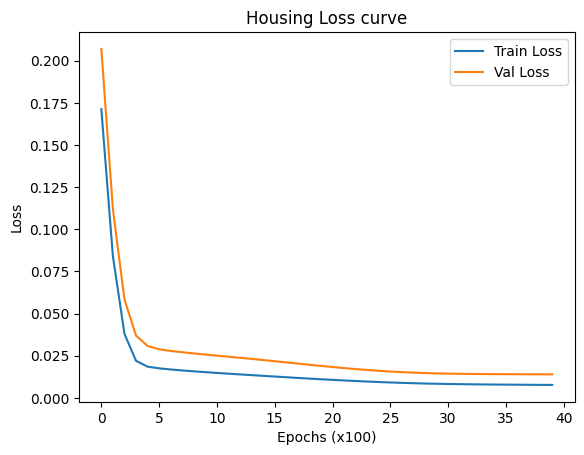

In [342]:
h_model = nn.Sequential(nn.Linear(12, 12),
                      nn.Tanh(),
                      nn.Linear(12, 12),
                      nn.Tanh(),
                      nn.Linear(12, 12),
                      nn.Tanh(),
                      nn.Linear(12, 1))

h_loss_fn = nn.MSELoss()
h_optimizer = optim.Adam(h_model.parameters(), lr=0.0001)
nn_reg(h_tr_x, h_tr_y, h_tst_x, h_txt_y, 4000, h_optimizer, h_loss_fn, h_model)

In [343]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

h_model.eval()

with torch.no_grad():
    h_tst_pred = h_model(h_tst_x).cpu().numpy()
    h_tst_true = h_txt_y.unsqueeze(1).cpu().numpy()

mse_norm = mean_squared_error(h_tst_true, h_tst_pred)
rmse_norm = np.sqrt(mse_norm)
r2 = r2_score(h_tst_true, h_tst_pred)
print("Breast Cancer Test Evaluation:")
print(f"MSE:  {mse_norm:.6f}")
print(f"RMSE: {rmse_norm:.6f}")
print(f"R²:   {r2:.6f}")

Breast Cancer Test Evaluation:
MSE:  0.013966
RMSE: 0.118178
R²:   0.631402


# Problem 2

In [322]:
cancer_data = pd.read_csv('/content/drive/My Drive/Fall26/ECGR4105/HW6/Cancer.csv')

In [323]:
def binary_map(x):
  return x.map({'M': 1, 'B': 0})

In [324]:
cancer_colm = ['radius_mean',	'texture_mean',	'perimeter_mean',	'area_mean',	'smoothness_mean',	'compactness_mean',	'concavity_mean',	'concave points_mean',	'symmetry_mean',	'fractal_dimension_mean',	'radius_se',	'texture_se',	'perimeter_se',	'area_se',	'smoothness_se'	,'compactness_se',	'concavity_se',	'concave points_se'	,'symmetry_se',	'fractal_dimension_se'	,'radius_worst',	'texture_worst',	'perimeter_worst',	'area_worst',	'smoothness_worst',	'compactness_worst',	'concavity_worst'	,'concave points_worst'	,'symmetry_worst'	,'fractal_dimension_worst']

cancer_data[['diagnosis']] = cancer_data[['diagnosis']].apply(binary_map)

cancer_data[cancer_colm] = scaler.fit_transform(cancer_data[cancer_colm])

c_train, c_test = train_test_split(cancer_data, train_size=0.8, test_size=0.2, random_state=42)

c_tr_x, c_tr_y = torch.tensor(c_train[cancer_colm].values).float(), torch.tensor(c_train['diagnosis'].values).float()
c_tst_x, c_txt_y = torch.tensor(c_test[cancer_colm].values).float(), torch.tensor(c_test['diagnosis'].values).float()
cancer_data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,1,0.521037,0.022658,0.545989,0.363733,0.593753,0.792037,0.703140,0.731113,...,0.141525,0.668310,0.450698,0.601136,0.619292,0.568610,0.912027,0.598462,0.418864,NaN
1,842517,1,0.643144,0.272574,0.615783,0.501591,0.289880,0.181768,0.203608,0.348757,...,0.303571,0.539818,0.435214,0.347553,0.154563,0.192971,0.639175,0.233590,0.222878,NaN
2,84300903,1,0.601496,0.390260,0.595743,0.449417,0.514309,0.431017,0.462512,0.635686,...,0.360075,0.508442,0.374508,0.483590,0.385375,0.359744,0.835052,0.403706,0.213433,NaN
3,84348301,1,0.210090,0.360839,0.233501,0.102906,0.811321,0.811361,0.565604,0.522863,...,0.385928,0.241347,0.094008,0.915472,0.814012,0.548642,0.884880,1.000000,0.773711,NaN
4,84358402,1,0.629893,0.156578,0.630986,0.489290,0.430351,0.347893,0.463918,0.518390,...,0.123934,0.506948,0.341575,0.437364,0.172415,0.319489,0.558419,0.157500,0.142595,NaN


Epoch: 500, Train Loss: 0.069429, Val Loss: 0.064806 | Train Acc: 94.07%, Val Acc: 95.61%
Epoch: 1000, Train Loss: 0.057809, Val Loss: 0.056030 | Train Acc: 96.70%, Val Acc: 97.37%
Epoch: 1500, Train Loss: 0.053744, Val Loss: 0.051548 | Train Acc: 97.36%, Val Acc: 97.37%
Epoch: 2000, Train Loss: 0.050316, Val Loss: 0.048204 | Train Acc: 97.36%, Val Acc: 97.37%
Epoch: 2500, Train Loss: 0.046740, Val Loss: 0.046325 | Train Acc: 97.14%, Val Acc: 96.49%


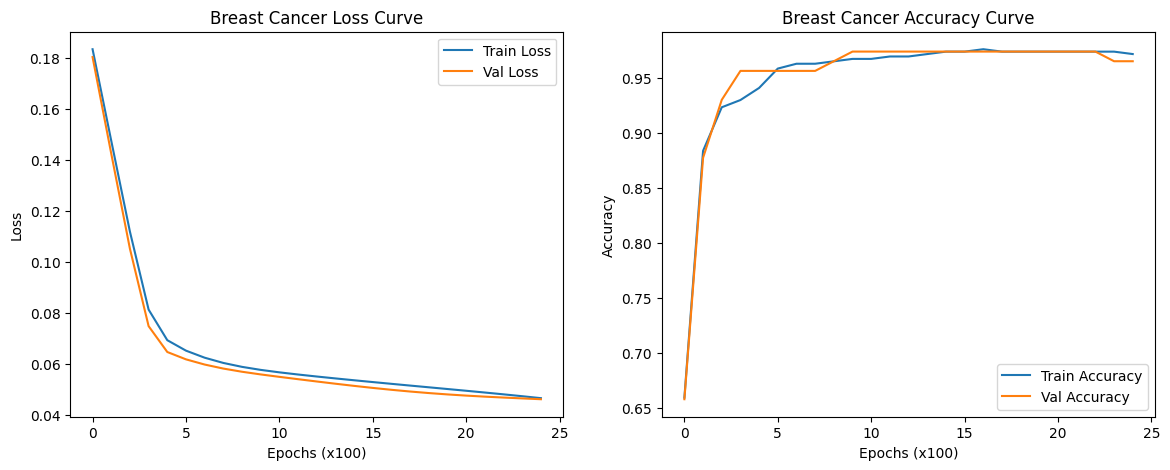

In [349]:
col_len = len(cancer_colm)
c_model = nn.Sequential(nn.Linear(col_len, col_len),
                      nn.Tanh(),
                      nn.Linear(col_len, col_len),
                      nn.Tanh(),
                      nn.Linear(col_len, col_len),
                      nn.Tanh(),
                      nn.Linear(col_len, 1))

c_loss_fn = nn.MSELoss()
c_optimizer = optim.Adam(c_model.parameters(), lr=0.0001)

nn_reg(c_tr_x, c_tr_y, c_tst_x, c_txt_y, 2500, c_optimizer, c_loss_fn, c_model, is_classification=True)

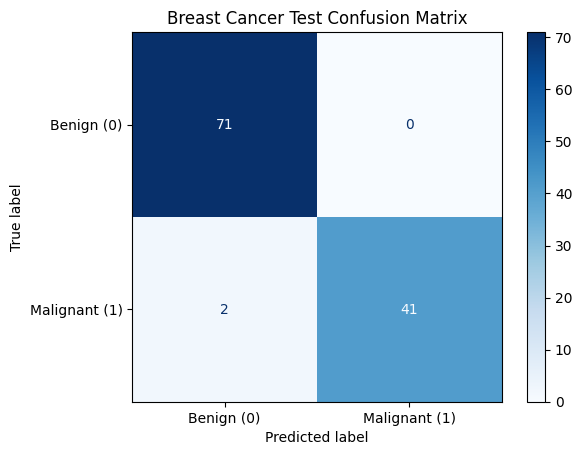

Confusion Matrix:
[[71  0]
 [ 2 41]]

Classification Metrics:
Accuracy:  0.982456
Precision: 1.000000
Recall:    0.953488
F1-Score:  0.976190


In [347]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

c_model.eval()

with torch.no_grad():
    c_tst_pred_raw = c_model(c_tst_x).cpu().numpy()
    c_tst_true = c_txt_y.cpu().numpy()

c_tst_pred_bin = (c_tst_pred_raw > 0.5).astype(int).flatten()

cm = confusion_matrix(c_tst_true, c_tst_pred_bin)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign (0)', 'Malignant (1)'])
disp.plot(cmap='Blues')
plt.title('Breast Cancer Test Confusion Matrix')
plt.show()

acc = accuracy_score(c_tst_true, c_tst_pred_bin)
precision = precision_score(c_tst_true, c_tst_pred_bin)
recall = recall_score(c_tst_true, c_tst_pred_bin)
f1 = f1_score(c_tst_true, c_tst_pred_bin)

print("Confusion Matrix:")
print(cm)
print("\nClassification Metrics:")
print(f"Accuracy:  {acc:.6f}")
print(f"Precision: {precision:.6f}")
print(f"Recall:    {recall:.6f}")
print(f"F1-Score:  {f1:.6f}")